# **Data Set Load**

In [ ]:
!pip install -q pandas pyarrow requests

In [ ]:
import pandas as pd

train_url = "https://raw.githubusercontent.com/PolyAI-LDN/task-specific-datasets/master/banking_data/train.csv"
test_url = "https://raw.githubusercontent.com/PolyAI-LDN/task-specific-datasets/master/banking_data/test.csv"

train_df = pd.read_csv(train_url)
test_df = pd.read_csv(test_url)

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

Train shape: (10003, 2)
Test shape: (3080, 2)


In [ ]:
print(train_df.columns.tolist())

display(train_df.head(10))

['text', 'category']


,text,category
0,I am still waiting on my card?,card_arrival
1,What can I do if my card still hasn't arrived ...,card_arrival
2,I have been waiting over a week. Is the card s...,card_arrival
3,Can I track my card while it is in the process...,card_arrival
4,"How do I know if I will get my card, or if it ...",card_arrival
5,When did you send me my new card?,card_arrival
6,Do you have info about the card on delivery?,card_arrival
7,What do I do if I still have not received my n...,card_arrival
8,Does the package with my card have tracking?,card_arrival
9,I ordered my card but it still isn't here,card_arrival


In [ ]:
print("Number of intents:", train_df["category"].nunique())

print("\nIntent names:")
print(sorted(train_df["category"].unique()))

Number of intents: 77

Intent names:
['Refund_not_showing_up', 'activate_my_card', 'age_limit', 'apple_pay_or_google_pay', 'atm_support', 'automatic_top_up', 'balance_not_updated_after_bank_transfer', 'balance_not_updated_after_cheque_or_cash_deposit', 'beneficiary_not_allowed', 'cancel_transfer', 'card_about_to_expire', 'card_acceptance', 'card_arrival', 'card_delivery_estimate', 'card_linking', 'card_not_working', 'card_payment_fee_charged', 'card_payment_not_recognised', 'card_payment_wrong_exchange_rate', 'card_swallowed', 'cash_withdrawal_charge', 'cash_withdrawal_not_recognised', 'change_pin', 'compromised_card', 'contactless_not_working', 'country_support', 'declined_card_payment', 'declined_cash_withdrawal', 'declined_transfer', 'direct_debit_payment_not_recognised', 'disposable_card_limits', 'edit_personal_details', 'exchange_charge', 'exchange_rate', 'exchange_via_app', 'extra_charge_on_statement', 'failed_transfer', 'fiat_currency_support', 'get_disposable_virtual_card', 'ge

In [ ]:
print("Missing values:")
print(train_df.isnull().sum())

print("\nDuplicate rows:", train_df.duplicated().sum())

print("\nTrain samples:", len(train_df))
print("Test samples:", len(test_df))

Missing values:
text        0
category    0
dtype: int64

Duplicate rows: 0

Train samples: 10003
Test samples: 3080


In [ ]:
for i in range(10):
    print("Text:", train_df.iloc[i]["text"])
    print("Intent:", train_df.iloc[i]["category"])
    print("-" * 70)

Text: I am still waiting on my card?
Intent: card_arrival
----------------------------------------------------------------------
Text: What can I do if my card still hasn't arrived after 2 weeks?
Intent: card_arrival
----------------------------------------------------------------------
Text: I have been waiting over a week. Is the card still coming?
Intent: card_arrival
----------------------------------------------------------------------
Text: Can I track my card while it is in the process of delivery?
Intent: card_arrival
----------------------------------------------------------------------
Text: How do I know if I will get my card, or if it is lost?
Intent: card_arrival
----------------------------------------------------------------------
Text: When did you send me my new card?
Intent: card_arrival
----------------------------------------------------------------------
Text: Do you have info about the card on delivery?
Intent: card_arrival
----------------------------------------

# **Intent Mapping + Train/Validation Split**

In [ ]:
# Get all unique intent names
intent_names = sorted(train_df["category"].unique())

print("Total intents:", len(intent_names))

for i, intent in enumerate(intent_names):
    print(i, "->", intent)

Total intents: 77
0 -> Refund_not_showing_up
1 -> activate_my_card
2 -> age_limit
3 -> apple_pay_or_google_pay
4 -> atm_support
5 -> automatic_top_up
6 -> balance_not_updated_after_bank_transfer
7 -> balance_not_updated_after_cheque_or_cash_deposit
8 -> beneficiary_not_allowed
9 -> cancel_transfer
10 -> card_about_to_expire
11 -> card_acceptance
12 -> card_arrival
13 -> card_delivery_estimate
14 -> card_linking
15 -> card_not_working
16 -> card_payment_fee_charged
17 -> card_payment_not_recognised
18 -> card_payment_wrong_exchange_rate
19 -> card_swallowed
20 -> cash_withdrawal_charge
21 -> cash_withdrawal_not_recognised
22 -> change_pin
23 -> compromised_card
24 -> contactless_not_working
25 -> country_support
26 -> declined_card_payment
27 -> declined_cash_withdrawal
28 -> declined_transfer
29 -> direct_debit_payment_not_recognised
30 -> disposable_card_limits
31 -> edit_personal_details
32 -> exchange_charge
33 -> exchange_rate
34 -> exchange_via_app
35 -> extra_charge_on_statement


In [ ]:
# Intent name -> numerical ID
label2id = {
    intent: i
    for i, intent in enumerate(intent_names)
}

# Numerical ID -> intent name
id2label = {
    i: intent
    for i, intent in enumerate(intent_names)
}

# Convert category to numerical label
train_df["label"] = train_df["category"].map(label2id)
test_df["label"] = test_df["category"].map(label2id)

print(train_df[["text", "category", "label"]].head(10))

                                                text      category  label
0                     I am still waiting on my card?  card_arrival     12
1  What can I do if my card still hasn't arrived ...  card_arrival     12
2  I have been waiting over a week. Is the card s...  card_arrival     12
3  Can I track my card while it is in the process...  card_arrival     12
4  How do I know if I will get my card, or if it ...  card_arrival     12
5                  When did you send me my new card?  card_arrival     12
6       Do you have info about the card on delivery?  card_arrival     12
7  What do I do if I still have not received my n...  card_arrival     12
8       Does the package with my card have tracking?  card_arrival     12
9          I ordered my card but it still isn't here  card_arrival     12


In [ ]:
print("Label mapping check:\n")

for i in range(10):
    print(
        f"ID: {i} | "
        f"Intent: {id2label[i]}"
    )

Label mapping check:

ID: 0 | Intent: Refund_not_showing_up
ID: 1 | Intent: activate_my_card
ID: 2 | Intent: age_limit
ID: 3 | Intent: apple_pay_or_google_pay
ID: 4 | Intent: atm_support
ID: 5 | Intent: automatic_top_up
ID: 6 | Intent: balance_not_updated_after_bank_transfer
ID: 7 | Intent: balance_not_updated_after_cheque_or_cash_deposit
ID: 8 | Intent: beneficiary_not_allowed
ID: 9 | Intent: cancel_transfer


In [ ]:
sample_intent = "pending_transfer"

sample_id = label2id[sample_intent]

print("Intent:", sample_intent)
print("ID:", sample_id)
print("Back to intent:", id2label[sample_id])

Intent: pending_transfer
ID: 49
Back to intent: pending_transfer


# **Train/Validation Split**

In [ ]:
from sklearn.model_selection import train_test_split

train_data, val_data = train_test_split(
    train_df,
    test_size=0.10,
    random_state=42,
    stratify=train_df["label"]
)

# Reset indexes
train_data = train_data.reset_index(drop=True)
val_data = val_data.reset_index(drop=True)

print("Training samples:", len(train_data))
print("Validation samples:", len(val_data))
print("Test samples:", len(test_df))

Training samples: 9002
Validation samples: 1001
Test samples: 3080


In [ ]:
print("Train intents:", train_data["label"].nunique())
print("Validation intents:", val_data["label"].nunique())
print("Test intents:", test_df["label"].nunique())

Train intents: 77
Validation intents: 77
Test intents: 77


### **Final dataset variables**

In [ ]:
X_train = train_data["text"].values
y_train = train_data["label"].values

X_val = val_data["text"].values
y_val = val_data["label"].values

X_test = test_df["text"].values
y_test = test_df["label"].values

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (9002,)
y_train: (9002,)
X_val: (1001,)
y_val: (1001,)
X_test: (3080,)
y_test: (3080,)


# **EDA**

In [ ]:
print("Train:", train_data.shape)
print("Validation:", val_data.shape)
print("Test:", test_df.shape)

Train: (9002, 3)
Validation: (1001, 3)
Test: (3080, 3)


In [ ]:
for i in range(10):
    print("Text:", train_data["text"][i])
    print("Intent:", train_data["category"][i])
    print()

Text: For adding money, which currencies do you accept?
Intent: supported_cards_and_currencies

Text: What's my limit for topping up?
Intent: top_up_limits

Text: When will my returned transaction show up on my account?
Intent: Refund_not_showing_up

Text: Which credit card top-ups do you accept?
Intent: supported_cards_and_currencies

Text: I tried to make a transfer but it failed. will you tell me why?
Intent: failed_transfer

Text: Can you tell me why the transfer isn't showing up on my account?
Intent: balance_not_updated_after_bank_transfer

Text: I did not get the right amount of cash from the ATM.
Intent: wrong_amount_of_cash_received

Text: My cash withdrawal was not entirely complete
Intent: wrong_amount_of_cash_received

Text: Why am I not allowed to add a certain beneficiary?
Intent: beneficiary_not_allowed

Text: I had an unexpected fee
Intent: transfer_fee_charged



In [ ]:
print(train_data["category"].value_counts())

category
card_payment_fee_charged                            168
direct_debit_payment_not_recognised                 164
balance_not_updated_after_cheque_or_cash_deposit    163
wrong_amount_of_cash_received                       162
cash_withdrawal_charge                              159
                                                   ... 
lost_or_stolen_card                                  74
card_swallowed                                       55
card_acceptance                                      53
virtual_card_not_working                             37
contactless_not_working                              32
Name: count, Length: 77, dtype: int64


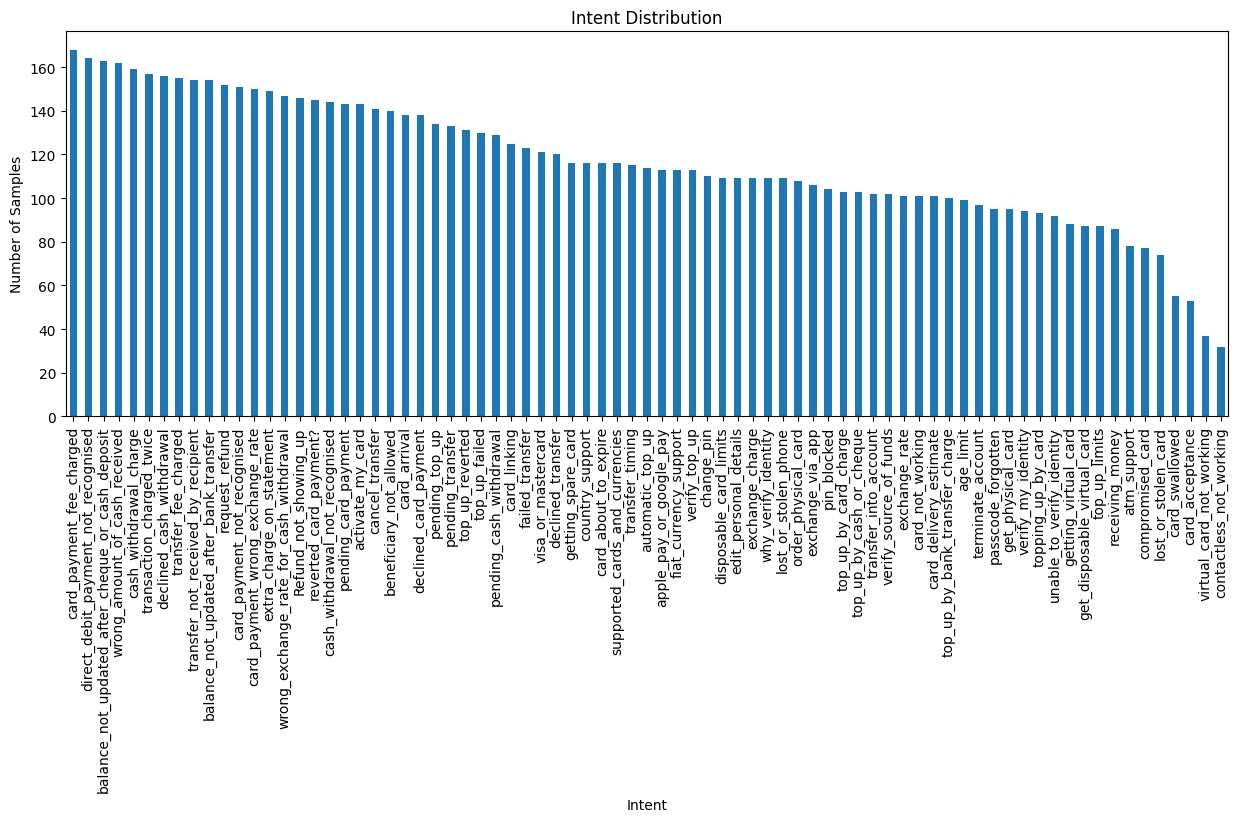

In [ ]:
import matplotlib.pyplot as plt

train_data["category"].value_counts().plot(kind="bar", figsize=(15, 5))

plt.title("Intent Distribution")
plt.xlabel("Intent")
plt.ylabel("Number of Samples")
plt.show()

In [ ]:
train_data["text_length"] = train_data["text"].apply(len)

print(train_data["text_length"].describe())

count    9002.000000
mean       59.725950
std        41.183641
min        13.000000
25%        36.000000
50%        47.000000
75%        64.000000
max       433.000000
Name: text_length, dtype: float64


In [ ]:
print("Shortest text:")
print(train_data.loc[train_data["text_length"].idxmin(), "text"])

print("\nLongest text:")
print(train_data.loc[train_data["text_length"].idxmax(), "text"])

Shortest text:
phone is gone

Longest text:
Hearing back from us regarding your important verification results may take 10 minutes to one hour time.  If verification results do fail, double-check to make sure all of your images are clear --  make sure your photos have no glare or blurring. Note: These photos need to be readable as well.  You also need to be 18 years of age or older.  You must be a resident of Switzerland or the European Economic Area to open a new account.


# **Text Preprocessing + Tokenization**

In [ ]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

### **Tokenizer**

In [ ]:
tokenizer = Tokenizer(num_words=10000, oov_token="<OOV>")

tokenizer.fit_on_texts(X_train)

print("Vocabulary size:", len(tokenizer.word_index))

Vocabulary size: 2305


### **Text → Sequence**

In [ ]:
X_train_seq = tokenizer.texts_to_sequences(X_train)
X_val_seq = tokenizer.texts_to_sequences(X_val)
X_test_seq = tokenizer.texts_to_sequences(X_test)

print(X_train[0])
print(X_train_seq[0])

For adding money, which currencies do you accept?
[12, 445, 20, 159, 117, 10, 18, 212]


### **Maximum length**

In [ ]:
lengths = [len(x) for x in X_train_seq]

print("Maximum length:", max(lengths))
print("Average length:", sum(lengths) / len(lengths))

Maximum length: 79
Average length: 12.0437680515441


### **Padding**

In [ ]:
MAX_LEN = 50

X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=MAX_LEN,
    padding="post"
)

X_val_pad = pad_sequences(
    X_val_seq,
    maxlen=MAX_LEN,
    padding="post"
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=MAX_LEN,
    padding="post"
)

print("Train shape:", X_train_pad.shape)
print("Validation shape:", X_val_pad.shape)
print("Test shape:", X_test_pad.shape)

Train shape: (9002, 50)
Validation shape: (1001, 50)
Test shape: (3080, 50)


In [ ]:
print("Original:")
print(X_train[0])

print("\nAfter tokenization:")
print(X_train_seq[0])

print("\nAfter padding:")
print(X_train_pad[0])

Original:
For adding money, which currencies do you accept?

After tokenization:
[12, 445, 20, 159, 117, 10, 18, 212]

After padding:
[ 12 445  20 159 117  10  18 212   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0]


### **Save tokenizer**

In [ ]:
import pickle

with open("tokenizer77.pkl", "wb") as file:
    pickle.dump(tokenizer, file)

print("Tokenizer saved successfully!")

Tokenizer saved successfully!


# **LSTM Model**

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

In [ ]:
vocab_size = 10000
embedding_dim = 128
num_classes = 77

print("Vocabulary:", vocab_size)
print("Classes:", num_classes)

Vocabulary: 10000
Classes: 77


In [ ]:
lstm_model = Sequential([
    Embedding(vocab_size, embedding_dim),
    LSTM(128),
    Dropout(0.3),
    Dense(64, activation="relu"),
    Dense(num_classes, activation="softmax")
])

lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
lstm_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
history_lstm = lstm_model.fit(
    X_train_pad,
    y_train,
    validation_data=(X_val_pad, y_val),
    epochs=15,
    batch_size=32
)

Epoch 1/15
282/282 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.3346 - loss: 1.9281 - val_accuracy: 0.3556 - val_loss: 2.1777
Epoch 2/15
282/282 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.4065 - loss: 1.7132 - val_accuracy: 0.4326 - val_loss: 1.9823
Epoch 3/15
282/282 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.4836 - loss: 1.5099 - val_accuracy: 0.4595 - val_loss: 1.8599
Epoch 4/15
282/282 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.5461 - loss: 1.3403 - val_accuracy: 0.5265 - val_loss: 1.7124
Epoch 5/15
282/282 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.6149 - loss: 1.1551 - val_accuracy: 0.5664 - val_loss: 1.6481
Epoch 6/15
282/282 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.6507 - loss: 1.0290 - val_accuracy: 0.5754 - val_loss: 1.5807
Epoch 7/15
282/282 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.6399 - loss: 1.1009 - val_accuracy: 0.6044 - val_loss: 1.4511
Epoch 8/15
282/282 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.7125 - loss: 0.8427 - val_accuracy: 

In [ ]:
test_loss, test_accuracy = lstm_model.evaluate(
    X_test_pad,
    y_test
)

print("LSTM Test Accuracy:", test_accuracy)

97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.7292 - loss: 1.1822
LSTM Test Accuracy: 0.7292208075523376


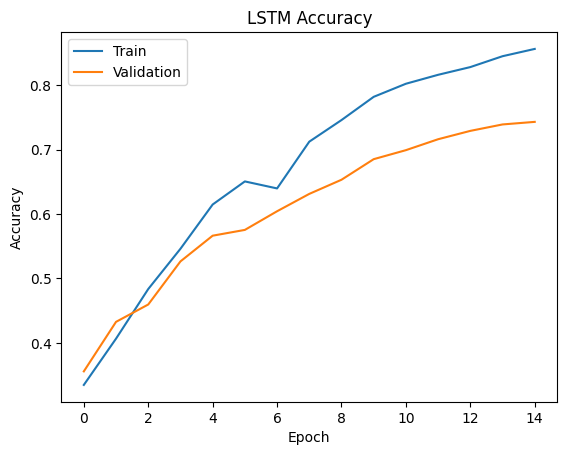

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history_lstm.history["accuracy"])
plt.plot(history_lstm.history["val_accuracy"])

plt.title("LSTM Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend(["Train", "Validation"])

plt.show()

In [ ]:
lstm_model.save("lstm_model.keras")

print("LSTM model saved!")

LSTM model saved!


# **GRU Model**

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, GRU, Dense, Dropout

In [ ]:
gru_model = Sequential([
    Embedding(10000, 128),
    GRU(128),
    Dropout(0.3),
    Dense(64, activation="relu"),
    Dense(77, activation="softmax")
])

gru_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
gru_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
history_gru = gru_model.fit(
    X_train_pad,
    y_train,
    validation_data=(X_val_pad, y_val),
    epochs=10,
    batch_size=32
)

Epoch 1/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.9320 - loss: 0.2105 - val_accuracy: 0.8092 - val_loss: 0.9042
Epoch 2/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.9389 - loss: 0.1986 - val_accuracy: 0.8062 - val_loss: 1.0247
Epoch 3/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.9425 - loss: 0.1753 - val_accuracy: 0.8172 - val_loss: 0.9173
Epoch 4/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.9492 - loss: 0.1563 - val_accuracy: 0.8192 - val_loss: 0.9396
Epoch 5/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.9539 - loss: 0.1454 - val_accuracy: 0.8312 - val_loss: 0.9389
Epoch 6/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9615 - loss: 0.1221 - val_accuracy: 0.8202 - val_loss: 1.0023
Epoch 7/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9650 - loss: 0.1112 - val_accuracy: 0.8142 - val_loss: 1.0538
Epoch 8/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.9677 - loss: 0.1072 - val_accuracy: 0

In [ ]:
test_loss, test_accuracy = gru_model.evaluate(
    X_test_pad,
    y_test
)

print("GRU Test Accuracy:", test_accuracy)

97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8334 - loss: 1.0176
GRU Test Accuracy: 0.8334415555000305


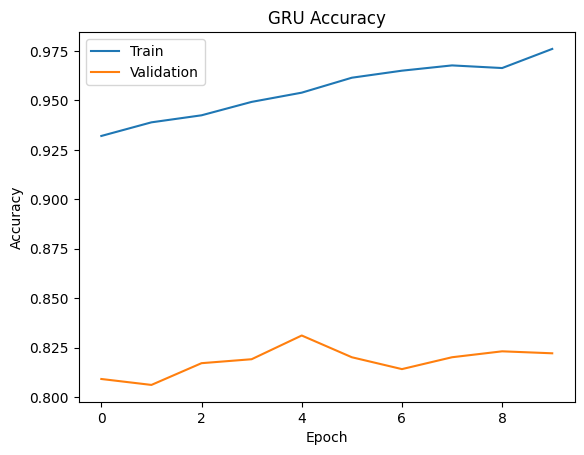

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history_gru.history["accuracy"])
plt.plot(history_gru.history["val_accuracy"])

plt.title("GRU Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend(["Train", "Validation"])

plt.show()

In [ ]:
gru_model.save("gru_model.keras")

print("GRU model saved!")

GRU model saved!


# **BiLSTM Model**

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Bidirectional
from tensorflow.keras.layers import Dense, Dropout

In [ ]:
bilstm_model = Sequential([
    Embedding(10000, 128),

    Bidirectional(
        LSTM(128)
    ),

    Dropout(0.3),

    Dense(64, activation="relu"),

    Dense(77, activation="softmax")
])

bilstm_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
bilstm_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
history_bilstm = bilstm_model.fit(
    X_train_pad,
    y_train,
    validation_data=(X_val_pad, y_val),
    epochs=10,
    batch_size=32
)

Epoch 1/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 7s 15ms/step - accuracy: 0.1251 - loss: 3.5884 - val_accuracy: 0.3586 - val_loss: 2.3052
Epoch 2/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.5112 - loss: 1.6771 - val_accuracy: 0.6434 - val_loss: 1.2178
Epoch 3/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.7146 - loss: 0.9590 - val_accuracy: 0.7363 - val_loss: 0.9323
Epoch 4/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.8073 - loss: 0.6653 - val_accuracy: 0.7912 - val_loss: 0.7710
Epoch 5/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.8579 - loss: 0.4808 - val_accuracy: 0.7962 - val_loss: 0.7786
Epoch 6/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.8802 - loss: 0.4016 - val_accuracy: 0.8142 - val_loss: 0.6993
Epoch 7/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.9064 - loss: 0.3249 - val_accuracy: 0.8132 - val_loss: 0.7387
Epoch 8/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.9172 - loss: 0.2781 - val_accu

In [ ]:
test_loss, test_accuracy = bilstm_model.evaluate(
    X_test_pad,
    y_test
)

print("BiLSTM Test Accuracy:", test_accuracy)

97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.8341 - loss: 0.6998
BiLSTM Test Accuracy: 0.8340908885002136


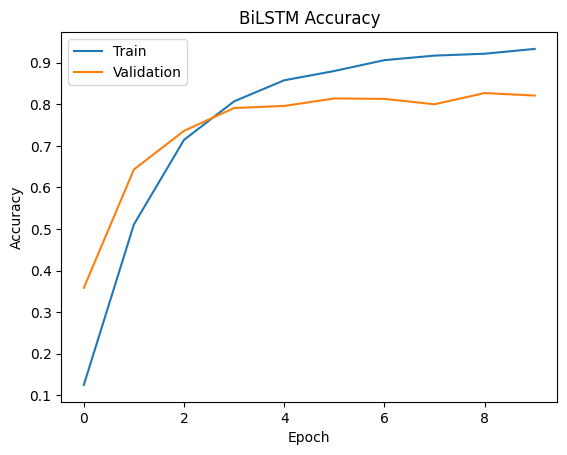

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history_bilstm.history["accuracy"])
plt.plot(history_bilstm.history["val_accuracy"])

plt.title("BiLSTM Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend(["Train", "Validation"])
plt.show()

In [ ]:
bilstm_model.save("bilstm_model.keras")

print("BiLSTM model saved!")

BiLSTM model saved!


# **Transformer Model**

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding,
    MultiHeadAttention,
    LayerNormalization,
    Dense,
    Dropout,
    GlobalAveragePooling1D
)

In [ ]:
class TransformerBlock(tf.keras.layers.Layer):

    def __init__(self, embed_dim, num_heads, ff_dim):
        super().__init__()

        self.attention = MultiHeadAttention(
            num_heads=num_heads,
            key_dim=embed_dim
        )

        self.ffn = Sequential([
            Dense(ff_dim, activation="relu"),
            Dense(embed_dim)
        ])

        self.norm1 = LayerNormalization()
        self.norm2 = LayerNormalization()

        self.dropout1 = Dropout(0.2)
        self.dropout2 = Dropout(0.2)

    def call(self, inputs, training=False):

        attention_output = self.attention(
            inputs,
            inputs
        )

        attention_output = self.dropout1(
            attention_output,
            training=training
        )

        out1 = self.norm1(
            inputs + attention_output
        )

        ffn_output = self.ffn(out1)

        ffn_output = self.dropout2(
            ffn_output,
            training=training
        )

        return self.norm2(
            out1 + ffn_output
        )

In [ ]:
embed_dim = 128
num_heads = 4
ff_dim = 128

transformer_model = Sequential([
    Embedding(10000, embed_dim),

    TransformerBlock(
        embed_dim,
        num_heads,
        ff_dim
    ),

    GlobalAveragePooling1D(),

    Dropout(0.3),

    Dense(64, activation="relu"),

    Dense(77, activation="softmax")
])

transformer_model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block               │ ?                      │   0 (unbuilt) │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ ?                      │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
transformer_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
history_transformer = transformer_model.fit(
    X_train_pad,
    y_train,
    validation_data=(X_val_pad, y_val),
    epochs=10,
    batch_size=32
)

Epoch 1/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 18s 31ms/step - accuracy: 0.0206 - loss: 4.3039 - val_accuracy: 0.0579 - val_loss: 3.9895
Epoch 2/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.4116 - loss: 2.2725 - val_accuracy: 0.7093 - val_loss: 1.0345
Epoch 3/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7664 - loss: 0.8292 - val_accuracy: 0.8032 - val_loss: 0.7459
Epoch 4/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8517 - loss: 0.5160 - val_accuracy: 0.8232 - val_loss: 0.7079
Epoch 5/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8871 - loss: 0.3843 - val_accuracy: 0.8232 - val_loss: 0.6982
Epoch 6/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9147 - loss: 0.2874 - val_accuracy: 0.8382 - val_loss: 0.7298
Epoch 7/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9253 - loss: 0.2554 - val_accuracy: 0.8332 - val_loss: 0.7575
Epoch 8/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9297 - loss: 0.2302 - val_accuracy: 

In [ ]:
test_loss, test_accuracy = transformer_model.evaluate(
    X_test_pad,
    y_test
)

print("Transformer Test Accuracy:", test_accuracy)

97/97 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step - accuracy: 0.8422 - loss: 0.7261
Transformer Test Accuracy: 0.8422077894210815


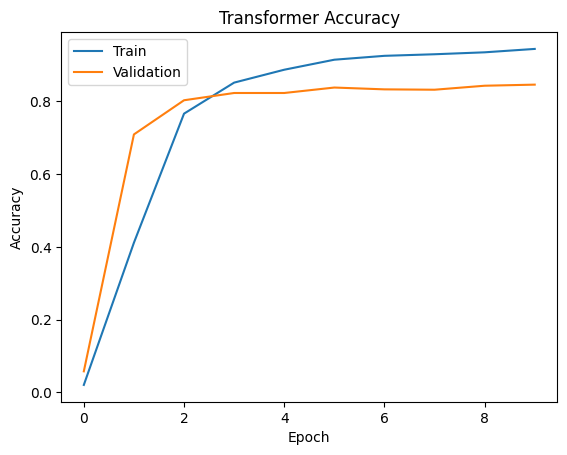

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history_transformer.history["accuracy"])
plt.plot(history_transformer.history["val_accuracy"])

plt.title("Transformer Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend(["Train", "Validation"])
plt.show()

In [ ]:
transformer_model.save("transformer_model.keras")

print("Transformer model saved!")

Transformer model saved!


# **Model Comparison**

In [ ]:
lstm_result = lstm_model.evaluate(X_test_pad, y_test, verbose=0)
gru_result = gru_model.evaluate(X_test_pad, y_test, verbose=0)
bilstm_result = bilstm_model.evaluate(X_test_pad, y_test, verbose=0)
transformer_result = transformer_model.evaluate(X_test_pad, y_test, verbose=0)

print("LSTM Accuracy:", lstm_result[1])
print("GRU Accuracy:", gru_result[1])
print("BiLSTM Accuracy:", bilstm_result[1])
print("Transformer Accuracy:", transformer_result[1])

LSTM Accuracy: 0.7292208075523376
GRU Accuracy: 0.8334415555000305
BiLSTM Accuracy: 0.8340908885002136
Transformer Accuracy: 0.8422077894210815


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import numpy as np
# Predictions
lstm_pred = np.argmax(lstm_model.predict(X_test_pad), axis=1)
gru_pred = np.argmax(gru_model.predict(X_test_pad), axis=1)
bilstm_pred = np.argmax(bilstm_model.predict(X_test_pad), axis=1)
transformer_pred = np.argmax(
    transformer_model.predict(X_test_pad),
    axis=1
)

97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step
97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
97/97 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step


In [ ]:
def get_scores(y_true, y_pred):
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(
        y_true, y_pred, average="weighted"
    )
    recall = recall_score(
        y_true, y_pred, average="weighted"
    )
    f1 = f1_score(
        y_true, y_pred, average="weighted"
    )

    return accuracy, precision, recall, f1

In [ ]:
lstm_scores = get_scores(y_test, lstm_pred)
gru_scores = get_scores(y_test, gru_pred)
bilstm_scores = get_scores(y_test, bilstm_pred)
transformer_scores = get_scores(y_test, transformer_pred)

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
results = pd.DataFrame(
    [lstm_scores, gru_scores, bilstm_scores, transformer_scores],
    columns=["Accuracy", "Precision", "Recall", "F1-Score"],
    index=["LSTM", "GRU", "BiLSTM", "Transformer"]
)

print(results)

             Accuracy  Precision    Recall  F1-Score
LSTM         0.729221   0.733389  0.729221  0.715180
GRU          0.833442   0.841571  0.833442  0.833508
BiLSTM       0.834091   0.845985  0.834091  0.834369
Transformer  0.842208   0.852496  0.842208  0.841858


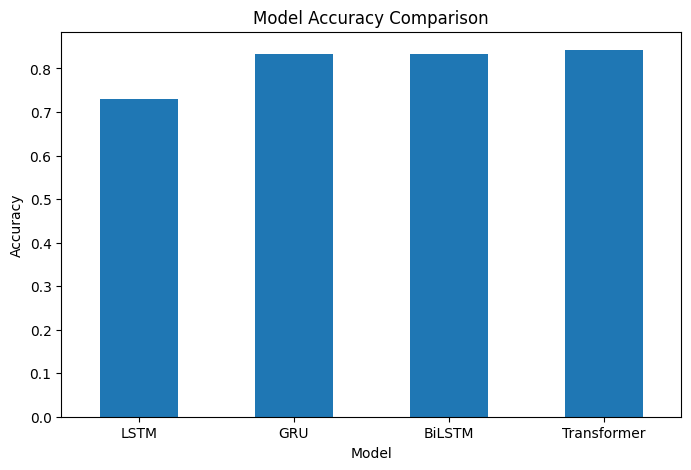

In [ ]:
results["Accuracy"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.show()

# **Best Model Select + Error Analysis**

In [68]:
best_model_name = results["F1-Score"].idxmax()

print("Best Model:", best_model_name)
print("Best F1-Score:", results.loc[best_model_name, "F1-Score"])

Best Model: Transformer
Best F1-Score: 0.8418583599065509


In [69]:
if best_model_name == "LSTM":
    best_model = lstm_model
    best_pred = lstm_pred

elif best_model_name == "GRU":
    best_model = gru_model
    best_pred = gru_pred

elif best_model_name == "BiLSTM":
    best_model = bilstm_model
    best_pred = bilstm_pred

else:
    best_model = transformer_model
    best_pred = transformer_pred

print("Selected:", best_model_name)

Selected: Transformer


In [70]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        best_pred,
        target_names=intent_names
    )
)

                                                  precision    recall  f1-score   support

                           Refund_not_showing_up       0.83      0.88      0.85        40
                                activate_my_card       0.93      0.97      0.95        40
                                       age_limit       0.90      0.90      0.90        40
                         apple_pay_or_google_pay       0.97      0.97      0.97        40
                                     atm_support       0.86      0.93      0.89        40
                                automatic_top_up       0.97      0.88      0.92        40
         balance_not_updated_after_bank_transfer       0.73      0.75      0.74        40
balance_not_updated_after_cheque_or_cash_deposit       0.91      0.78      0.84        40
                         beneficiary_not_allowed       0.89      0.80      0.84        40
                                 cancel_transfer       0.90      0.90      0.90        40
         

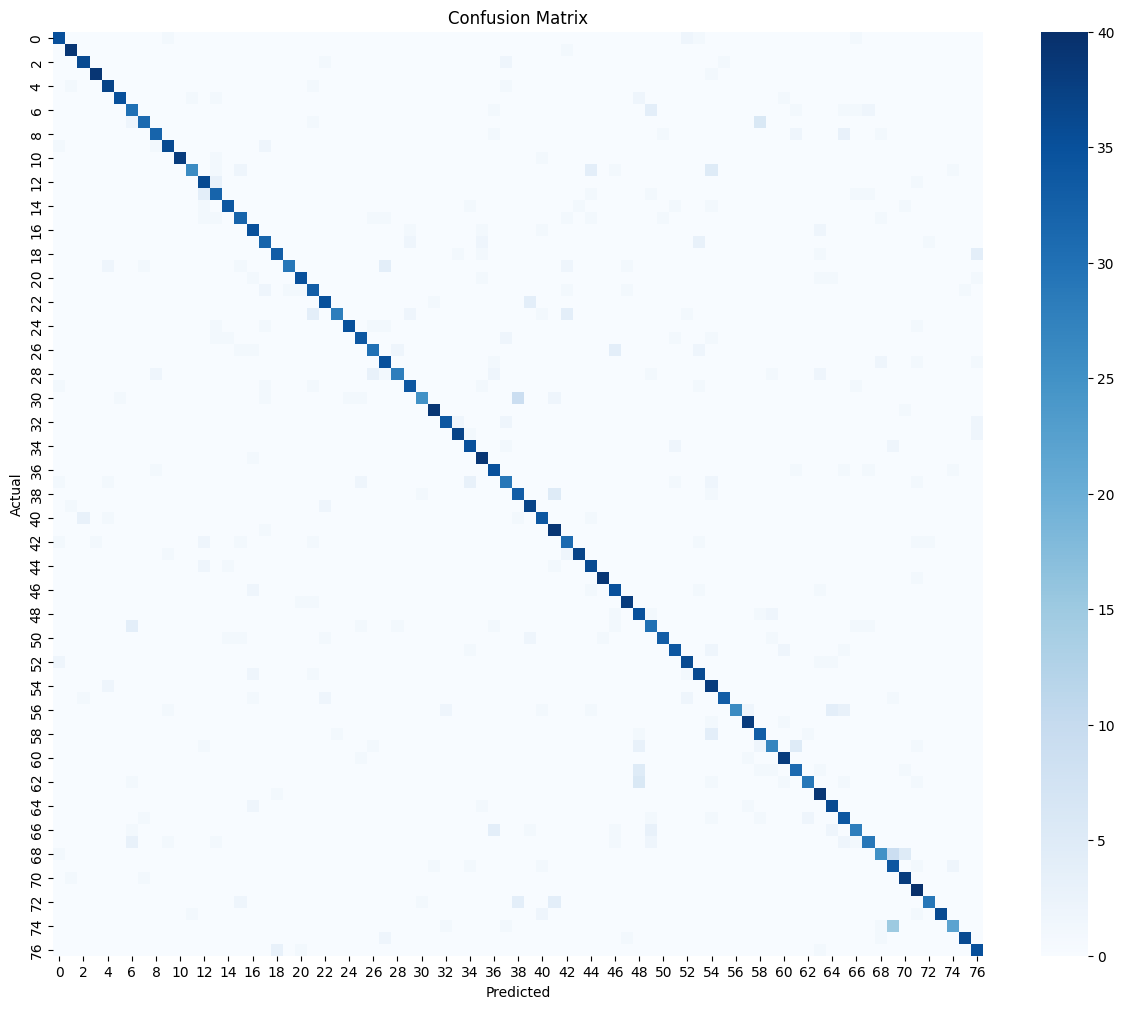

In [71]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_test, best_pred)

plt.figure(figsize=(15, 12))

sns.heatmap(
    cm,
    cmap="Blues"
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

# **Wrong Predictions**

In [72]:
wrong = np.where(y_test != best_pred)[0]

print("Total wrong predictions:", len(wrong))

Total wrong predictions: 486


In [73]:
for i in wrong[:10]:

    print("Text:", X_test[i])
    print("Actual:", id2label[y_test[i]])
    print("Predicted:", id2label[best_pred[i]])
    print("-" * 60)

Text: How do I locate my card?
Actual: card_arrival
Predicted: verify_top_up
------------------------------------------------------------
Text: When will I get my card?
Actual: card_arrival
Predicted: card_delivery_estimate
------------------------------------------------------------
Text: Is it normal to have to wait over a week for my new card?
Actual: card_arrival
Predicted: card_delivery_estimate
------------------------------------------------------------
Text: How long does a card delivery take?
Actual: card_arrival
Predicted: card_delivery_estimate
------------------------------------------------------------
Text: How do I add the card to my account?
Actual: card_linking
Predicted: supported_cards_and_currencies
------------------------------------------------------------
Text: Can you tell me how to link one of your cards that I already have?
Actual: card_linking
Predicted: lost_or_stolen_phone
------------------------------------------------------------
Text: How do I view the

# **Custom Text Prediction**

In [74]:
def predict_intent(text):

    # Text ko sequence me convert karo
    sequence = tokenizer.texts_to_sequences([text])

    # Padding
    padded = pad_sequences(
        sequence,
        maxlen=50,
        padding="post"
    )

    # Prediction
    prediction = best_model.predict(padded, verbose=0)

    # Best class
    predicted_id = np.argmax(prediction[0])

    # Confidence
    confidence = prediction[0][predicted_id]

    # Intent name
    intent = id2label[predicted_id]

    return intent, confidence

In [75]:
text = "Why is my transfer pending?"

intent, confidence = predict_intent(text)

print("Text:", text)
print("Intent:", intent)
print("Confidence:", round(confidence * 100, 2), "%")

Text: Why is my transfer pending?
Intent: pending_transfer
Confidence: 99.91 %


In [76]:
queries = [
    "Why is my transfer pending?",
    "I cannot withdraw money from the ATM",
    "How can I transfer money?",
    "My card payment was declined",
    "I lost my card",
    "What is my account balance?"
]

for text in queries:

    intent, confidence = predict_intent(text)

    print("Text:", text)
    print("Intent:", intent)
    print("Confidence:", round(confidence * 100, 2), "%")
    print("-" * 60)

Text: Why is my transfer pending?
Intent: pending_transfer
Confidence: 99.91 %
------------------------------------------------------------
Text: I cannot withdraw money from the ATM
Intent: declined_cash_withdrawal
Confidence: 98.0 %
------------------------------------------------------------
Text: How can I transfer money?
Intent: transfer_into_account
Confidence: 97.07 %
------------------------------------------------------------
Text: My card payment was declined
Intent: declined_card_payment
Confidence: 98.97 %
------------------------------------------------------------
Text: I lost my card
Intent: lost_or_stolen_card
Confidence: 99.98 %
------------------------------------------------------------
Text: What is my account balance?
Intent: verify_source_of_funds
Confidence: 55.0 %
------------------------------------------------------------


In [77]:
text = input("Enter your banking query: ")

intent, confidence = predict_intent(text)

print("\nPredicted Intent:", intent)
print("Confidence:", round(confidence * 100, 2), "%")


Enter your banking query: my payment are not credit

Predicted Intent: pending_card_payment
Confidence: 96.44 %


# **Top-3 Prediction + Confidence**

In [78]:
def predict_top3(text):

    # Text ko sequence me convert karo
    sequence = tokenizer.texts_to_sequences([text])

    # Padding
    padded = pad_sequences(
        sequence,
        maxlen=50,
        padding="post"
    )

    # Model prediction
    prediction = best_model.predict(
        padded,
        verbose=0
    )[0]

    # Top 3 IDs
    top3_ids = np.argsort(prediction)[-3:][::-1]

    results = []

    for i in top3_ids:
        results.append({
            "intent": id2label[i],
            "confidence": prediction[i]
        })

    return results

In [79]:
text = "Why is my transfer pending?"

results = predict_top3(text)

for result in results:
    print(
        result["intent"],
        "->",
        round(result["confidence"] * 100, 2),
        "%"
    )

pending_transfer -> 99.91 %
declined_transfer -> 0.04 %
balance_not_updated_after_bank_transfer -> 0.02 %


In [80]:
def predict_with_threshold(text):

    results = predict_top3(text)

    best = results[0]

    if best["confidence"] < 0.50:
        return "unknown", best["confidence"]

    return best["intent"], best["confidence"]

In [81]:
text = "Why is my transfer pending?"

intent, confidence = predict_with_threshold(text)

print("Intent:", intent)
print("Confidence:", round(confidence * 100, 2), "%")

Intent: pending_transfer
Confidence: 99.91 %


# **Final Model & Files Save**

In [82]:
import os

os.makedirs("models", exist_ok=True)

print("Models folder ready")

Models folder ready


In [83]:
best_model.save("models/best_model.keras")

print("Best model saved!")

Best model saved!


In [84]:
import pickle

with open("models/tokenizerbest.pkl", "wb") as file:
    pickle.dump(tokenizer, file)

print("Tokenizer saved!")

Tokenizer saved!


In [85]:
with open("models/id2label.pkl", "wb") as file:
    pickle.dump(id2label, file)

print("Intent mapping saved!")

Intent mapping saved!


In [86]:
print(os.listdir("models"))

['id2label.pkl', 'best_model.keras', 'tokenizerbest.pkl']


In [87]:
from google.colab import files

files.download("models/best_model.keras")
files.download("models/tokenizerbest.pkl")
files.download("models/id2label.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>